In [2]:
%%time

import kplex_dev
import data_splits
import warnings
warnings.filterwarnings('ignore')

timeout_replacement = 1800
excel_path = "kplex_ML_data.xlsx"

cat_df, dfs = kplex_dev.load_excel_data(excel_path, timeout_replacement)
cat_df

CPU times: total: 1.17 s
Wall time: 1.29 s


,dataset,n,m,d_avg,d_max,core_max,kcore_list,UMKP,AltRB,kPEX,Pivot_Br,S_Br,k_value
0,MANN-a81,3321.0,5506380.0,1658.0488,3317.0,3280.0,"[(3280,3321)]",1459.5,1800.0,1468.1,1477.4,1504.7,20
1,wikipedia_link_sr,1810.0,1637059.0,904.4525,1809.0,1798.0,"[(1795,1810),(1796,1808),(1797,1804),(1798,1803)]",22.6,18.0,737.7,740.4,738.1,20
2,scc_reality,1332.0,880733.0,661.2110,1331.0,1235.0,"[(1230,1332),(1231,1330),(1232,1309),(1233,126...",1800.0,1214.8,9.4,9.7,9.0,20
3,web-wikipedia_link_en13-all,432.0,93085.0,215.4745,431.0,427.0,"[(427,432)]",239.3,287.1,517.7,504.4,516.7,20
4,livejournal-links,442.0,94435.0,213.6538,441.0,371.0,"[(369,442),(370,409),(371,386)]",1.3,1.6,1.6,1.6,1.6,20
...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,soc-flixster,264.0,11792.0,44.6667,150.0,67.0,"[(52,264),(53,262),(54,261),(55,260),(56,256),...",2.0,0.6,0.5,0.5,2.4,2
756,edit-ukwiki,281.0,14183.0,50.4733,280.0,65.0,"[(40,281),(41,279),(42,275),(43,271),(44,268),...",1.2,1.1,0.6,0.6,0.5,2
757,johnson8-4-4,70.0,1855.0,26.5000,53.0,53.0,"[(53,70)]",0.8,0.9,1.1,1.1,0.3,2
758,hamming6-2,64.0,1824.0,28.5000,57.0,57.0,"[(57,64)]",0.2,0.3,0.2,0.2,0.3,2


In [3]:
# test run

kplex_dev.process_kcore_list_to_statistics(cat_df)
cat_df

,dataset,n,m,d_avg,d_max,core_max,UMKP,AltRB,kPEX,Pivot_Br,S_Br,k_value,shell_num,core_min,shell_avgSize,shell_maxSize,shell_minSize,shell_stdSize
0,MANN-a81,3321.0,5506380.0,1658.0488,3317.0,3280.0,1459.5,1800.0,1468.1,1477.4,1504.7,20,1,3280,3321.000000,3321,3321,0.000000
1,wikipedia_link_sr,1810.0,1637059.0,904.4525,1809.0,1798.0,22.6,18.0,737.7,740.4,738.1,20,4,1795,1806.250000,1810,1803,2.861381
2,scc_reality,1332.0,880733.0,661.2110,1331.0,1235.0,1800.0,1214.8,9.4,9.7,9.0,20,6,1230,1290.333333,1332,1236,35.714921
3,web-wikipedia_link_en13-all,432.0,93085.0,215.4745,431.0,427.0,239.3,287.1,517.7,504.4,516.7,20,1,427,432.000000,432,432,0.000000
4,livejournal-links,442.0,94435.0,213.6538,441.0,371.0,1.3,1.6,1.6,1.6,1.6,20,3,369,412.333333,442,386,22.983086
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,soc-flixster,264.0,11792.0,44.6667,150.0,67.0,2.0,0.6,0.5,0.5,2.4,2,16,52,215.000000,264,125,56.656862
756,edit-ukwiki,281.0,14183.0,50.4733,280.0,65.0,1.2,1.1,0.6,0.6,0.5,2,26,40,235.384615,281,168,34.703222
757,johnson8-4-4,70.0,1855.0,26.5000,53.0,53.0,0.8,0.9,1.1,1.1,0.3,2,1,53,70.000000,70,70,0.000000
758,hamming6-2,64.0,1824.0,28.5000,57.0,57.0,0.2,0.3,0.2,0.2,0.3,2,1,57,64.000000,64,64,0.000000


In [4]:
import kplex_dev

epsilon = 0.001 # need to set !!!
scheme = kplex_dev.W_TIME_MIN_X_W_LOG_TIME_RATIO

kplex_dev.assign_weights(cat_df, scheme, epsilon)
display(cat_df)
kplex_dev.export_sorted(cat_df)

,dataset,n,m,d_avg,d_max,core_max,UMKP,AltRB,kPEX,Pivot_Br,S_Br,k_value,shell_num,core_min,shell_avgSize,shell_maxSize,shell_minSize,shell_stdSize,weight
0,MANN-a81,3321.0,5506380.0,1658.0488,3317.0,3280.0,1459.5,1800.0,1468.1,1477.4,1504.7,20,1,3280,3321.000000,3321,3321,0.000000,306.046574
1,wikipedia_link_sr,1810.0,1637059.0,904.4525,1809.0,1798.0,22.6,18.0,737.7,740.4,738.1,20,4,1795,1806.250000,1810,1803,2.861381,66.902739
2,scc_reality,1332.0,880733.0,661.2110,1331.0,1235.0,1800.0,1214.8,9.4,9.7,9.0,20,6,1230,1290.333333,1332,1236,35.714921,47.684856
3,web-wikipedia_link_en13-all,432.0,93085.0,215.4745,431.0,427.0,239.3,287.1,517.7,504.4,516.7,20,1,427,432.000000,432,432,0.000000,184.662528
4,livejournal-links,442.0,94435.0,213.6538,441.0,371.0,1.3,1.6,1.6,1.6,1.6,20,3,369,412.333333,442,386,22.983086,0.269931
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,soc-flixster,264.0,11792.0,44.6667,150.0,67.0,2.0,0.6,0.5,0.5,2.4,2,16,52,215.000000,264,125,56.656862,0.784308
756,edit-ukwiki,281.0,14183.0,50.4733,280.0,65.0,1.2,1.1,0.6,0.6,0.5,2,26,40,235.384615,281,168,34.703222,0.437734
757,johnson8-4-4,70.0,1855.0,26.5000,53.0,53.0,0.8,0.9,1.1,1.1,0.3,2,1,53,70.000000,70,70,0.000000,0.389785
758,hamming6-2,64.0,1824.0,28.5000,57.0,57.0,0.2,0.3,0.2,0.2,0.3,2,1,57,64.000000,64,64,0.000000,0.081093


# Training with XGBoost (Extreme Gradient Boosting)

## Data reformatting

In [5]:
cat_df.dtypes

dataset           object
n                float64
m                float64
d_avg            float64
d_max            float64
core_max         float64
UMKP             float64
AltRB            float64
kPEX             float64
Pivot_Br         float64
S_Br             float64
k_value            int64
shell_num          int64
core_min           int64
shell_avgSize    float64
shell_maxSize      int32
shell_minSize      int32
shell_stdSize    float64
weight           float64
dtype: object

In [6]:
import pandas as pd

# List of columns to convert from float to int
int_cols = ['n', 'm', 'd_max', 'core_max', 'shell_maxSize', 'shell_minSize']

# Convert to int (using pd.to_numeric() to handle potential NaN values)
for col in int_cols:
    cat_df[col] = pd.to_numeric(cat_df[col], errors='coerce').astype('Int64')  # Capital 'Int64' supports NA values
    
cat_df.dtypes

dataset           object
n                  Int64
m                  Int64
d_avg            float64
d_max              Int64
core_max           Int64
UMKP             float64
AltRB            float64
kPEX             float64
Pivot_Br         float64
S_Br             float64
k_value            int64
shell_num          int64
core_min           int64
shell_avgSize    float64
shell_maxSize      Int64
shell_minSize      Int64
shell_stdSize    float64
weight           float64
dtype: object

In [7]:
cat_df

,dataset,n,m,d_avg,d_max,core_max,UMKP,AltRB,kPEX,Pivot_Br,S_Br,k_value,shell_num,core_min,shell_avgSize,shell_maxSize,shell_minSize,shell_stdSize,weight
0,MANN-a81,3321,5506380,1658.0488,3317,3280,1459.5,1800.0,1468.1,1477.4,1504.7,20,1,3280,3321.000000,3321,3321,0.000000,306.046574
1,wikipedia_link_sr,1810,1637059,904.4525,1809,1798,22.6,18.0,737.7,740.4,738.1,20,4,1795,1806.250000,1810,1803,2.861381,66.902739
2,scc_reality,1332,880733,661.2110,1331,1235,1800.0,1214.8,9.4,9.7,9.0,20,6,1230,1290.333333,1332,1236,35.714921,47.684856
3,web-wikipedia_link_en13-all,432,93085,215.4745,431,427,239.3,287.1,517.7,504.4,516.7,20,1,427,432.000000,432,432,0.000000,184.662528
4,livejournal-links,442,94435,213.6538,441,371,1.3,1.6,1.6,1.6,1.6,20,3,369,412.333333,442,386,22.983086,0.269931
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,soc-flixster,264,11792,44.6667,150,67,2.0,0.6,0.5,0.5,2.4,2,16,52,215.000000,264,125,56.656862,0.784308
756,edit-ukwiki,281,14183,50.4733,280,65,1.2,1.1,0.6,0.6,0.5,2,26,40,235.384615,281,168,34.703222,0.437734
757,johnson8-4-4,70,1855,26.5000,53,53,0.8,0.9,1.1,1.1,0.3,2,1,53,70.000000,70,70,0.000000,0.389785
758,hamming6-2,64,1824,28.5000,57,57,0.2,0.3,0.2,0.2,0.3,2,1,57,64.000000,64,64,0.000000,0.081093


In [8]:
# Define column order (non-metric columns first, then performance metrics)
new_order = [
    'dataset', 'k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max', 
    'core_min', 'shell_num', 
    'shell_avgSize', 'shell_maxSize', 'shell_minSize', 'shell_stdSize',
    'weight',
    'UMKP', 'AltRB', 'kPEX', 'Pivot_Br', 'S_Br'
]

cat_df = cat_df[new_order]

In [9]:
cat_df

,dataset,k_value,n,m,d_avg,d_max,core_max,core_min,shell_num,shell_avgSize,shell_maxSize,shell_minSize,shell_stdSize,weight,UMKP,AltRB,kPEX,Pivot_Br,S_Br
0,MANN-a81,20,3321,5506380,1658.0488,3317,3280,3280,1,3321.000000,3321,3321,0.000000,306.046574,1459.5,1800.0,1468.1,1477.4,1504.7
1,wikipedia_link_sr,20,1810,1637059,904.4525,1809,1798,1795,4,1806.250000,1810,1803,2.861381,66.902739,22.6,18.0,737.7,740.4,738.1
2,scc_reality,20,1332,880733,661.2110,1331,1235,1230,6,1290.333333,1332,1236,35.714921,47.684856,1800.0,1214.8,9.4,9.7,9.0
3,web-wikipedia_link_en13-all,20,432,93085,215.4745,431,427,427,1,432.000000,432,432,0.000000,184.662528,239.3,287.1,517.7,504.4,516.7
4,livejournal-links,20,442,94435,213.6538,441,371,369,3,412.333333,442,386,22.983086,0.269931,1.3,1.6,1.6,1.6,1.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,soc-flixster,2,264,11792,44.6667,150,67,52,16,215.000000,264,125,56.656862,0.784308,2.0,0.6,0.5,0.5,2.4
756,edit-ukwiki,2,281,14183,50.4733,280,65,40,26,235.384615,281,168,34.703222,0.437734,1.2,1.1,0.6,0.6,0.5
757,johnson8-4-4,2,70,1855,26.5000,53,53,53,1,70.000000,70,70,0.000000,0.389785,0.8,0.9,1.1,1.1,0.3
758,hamming6-2,2,64,1824,28.5000,57,57,57,1,64.000000,64,64,0.000000,0.081093,0.2,0.3,0.2,0.2,0.3


## XGBoost Classification


### **Balanced train-test split based on Y**

#### Normal Training

In [10]:
from data_splits import prepare_train_test_strat_Y
from sklearn.preprocessing import LabelEncoder

X_train, X_test, y_train_str, y_test_str, weights_train, weights_test = prepare_train_test_strat_Y(cat_df, test_size=0.2)

# Label‐encode the string targets into integers 0…4 for XGBoost ---
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)     # e.g. ['AltRB','UMKP',…] → [0,3,…]
y_test  = le.transform(y_test_str)          # uses the same mapping

print("Label ↔ Algorithm mapping:")
for idx, label in enumerate(le.classes_):
    print(f"  {idx} ➔ {label}")

Label ↔ Algorithm mapping:
  0 ➔ AltRB
  1 ➔ Pivot_Br
  2 ➔ S_Br
  3 ➔ UMKP
  4 ➔ kPEX


In [11]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
algorithms = ['UMKP', 'AltRB', 'kPEX', 'Pivot_Br', 'S_Br']

# Train XGBoost with sample weights
xgb_strat_y = XGBClassifier(
     objective="multi:softprob",
     num_class=len(algorithms),      # = 5 in your case
     n_estimators=400,
     max_depth=15,
     learning_rate=0.1,              # you can tune this later
     subsample=1.0,
     colsample_bytree=1.0,
     use_label_encoder=False,
     eval_metric="mlogloss",
     random_state=42
 )

xgb_strat_y.fit(X_train, y_train, sample_weight=weights_train)

# Reversing mapping from integer labels to algorithm names
y_pred_int = xgb_strat_y.predict(X_test)
y_pred_str = le.inverse_transform(y_pred_int)

# Evaluate
y_pred = xgb_strat_y.predict(X_test)
print("Classification Report:")
print(classification_report(y_test_str, y_pred_str, sample_weight=weights_test))

report_dict = classification_report(
    y_test,
    y_pred,
    sample_weight=weights_test,
    output_dict=True
)
classif_df = pd.DataFrame(report_dict).T  # transpose to have metrics as columns

# Feature importance
importances = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb_strat_y.feature_importances_
}).sort_values('importance', ascending=False)

print("\nFeature Importances:")
print(importances)

Classification Report:
              precision    recall  f1-score   support

       AltRB       0.92      0.51      0.66 1640.270549672929
    Pivot_Br       0.15      0.23      0.19 870.9895672609558
        S_Br       0.80      0.90      0.85 2890.803767280769
        UMKP       0.58      0.20      0.30 1409.7178679964375
        kPEX       0.88      0.96      0.92 8862.24533427892

    accuracy                           0.79 15674.027086490012
   macro avg       0.67      0.56      0.58 15674.027086490012
weighted avg       0.80      0.79      0.78 15674.027086490012


Feature Importances:
          feature  importance
11  shell_stdSize    0.158274
2               m    0.144572
4           d_max    0.119840
5        core_max    0.112310
6        core_min    0.092071
10  shell_minSize    0.084999
3           d_avg    0.073643
7       shell_num    0.069399
8   shell_avgSize    0.057249
0         k_value    0.050075
1               n    0.037569
9   shell_maxSize    0.000000


In [13]:
## For exporting classification reports to a temp XL file.

from write_utils import append_report_to_excel

append_report_to_excel(
    filename="temp_results.xlsx",
    heading="Balanced train-test split based on Y for XGB",
    classif_report_df=classif_df,
    feat_importances_df=importances,
    sheet_name="Sheet1"    # or whatever your sheet is called
)


#### Hyperparameter Tuning and 5-fold CV

In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import classification_report

# ——— 1. Prepare your features, target, and weights ————————————————
from data_splits import prepare_train_test_strat_Y
X_train, X_test, y_train_str, y_test_str, weights_train, weights_test = prepare_train_test_strat_Y(cat_df, test_size=0.2)

le = LabelEncoder()
y_train = le.fit_transform(y_train_str)     # e.g. ['AltRB','UMKP',…] → [0,3,…]
y_test  = le.transform(y_test_str)  

# ——— 2. Define parameter grid for XGBoost ————————————————
param_grid = {
    "n_estimators":    [100, 200, 400],
    "max_depth":       [6, 10, 15],
    "learning_rate":   [0.01, 0.1],
    "subsample":       [0.8, 1.0],
    "colsample_bytree":[0.8, 1.0],
}

# ——— 3. Set up Stratified K-Fold for CV ————————————————
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# ——— 4. Instantiate base XGBClassifier ————————————————
xgb_base = XGBClassifier(
    objective="multi:softprob",
    num_class=len(algorithms),
    use_label_encoder=False,
    eval_metric="mlogloss",
    random_state=42
)

# ——— 5. Wrap in GridSearchCV ——————————————————————————
grid_xgb_1 = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# ——— 6. Fit using sample weights ————————————————————
grid_xgb_1.fit(X_train, y_train, sample_weight=weights_train)


# ——— 7. Inspect best parameters & CV score ——————————————————
print("Best params (XGB):", grid_xgb_1.best_params_)
print("Best CV accuracy:", grid_xgb_1.best_score_)




Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best params (RF): {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}
Best CV accuracy: 0.43049077619213366


In [16]:
# 8) Evaluate on hold‐out test set

# Reversing mapping from integer labels to algorithm names
y_pred_int = grid_xgb_1.predict(X_test)
y_pred_str = le.inverse_transform(y_pred_int)


print("\nClassification Report on Test Set:")
print(classification_report(
    y_test_str,
    y_pred_str,
    sample_weight=weights_test
))

report_dict_1 = classification_report(
    y_test_str,
    y_pred_str,
    sample_weight=weights_test,
    output_dict=True
)
classif_df_strat_Y = pd.DataFrame(report_dict_1).T  # transpose to have metrics as columns

# 9) Feature importances
importances = pd.DataFrame({
    'feature': X_train.columns,
    'importance': grid_xgb_1.best_estimator_.feature_importances_
}).sort_values('importance', ascending=False)

print("\nFeature Importances:")
print(importances)


Classification Report on Test Set:
              precision    recall  f1-score   support

       AltRB       0.90      0.49      0.63 1640.270549672929
    Pivot_Br       0.43      0.17      0.24 870.9895672609558
        S_Br       0.66      0.90      0.76 2890.803767280769
        UMKP       0.84      0.20      0.32 1409.7178679964375
        kPEX       0.86      0.99      0.92 8862.24533427892

    accuracy                           0.80 15674.027086490012
   macro avg       0.74      0.55      0.57 15674.027086490012
weighted avg       0.80      0.80      0.77 15674.027086490012


Feature Importances:
          feature  importance
11  shell_stdSize    0.144282
2               m    0.140988
4           d_max    0.137996
8   shell_avgSize    0.096391
5        core_max    0.092685
7       shell_num    0.084468
6        core_min    0.084005
10  shell_minSize    0.079759
3           d_avg    0.074139
0         k_value    0.043418
1               n    0.021867
9   shell_maxSize    0.000

### **Balanced train-test split based on both Y and k**

#### Normal Training

In [17]:
from data_splits import prepare_train_test_strat_Y_K
from sklearn.preprocessing import LabelEncoder

X_train, X_test, y_train_str, y_test_str, weights_train, weights_test = prepare_train_test_strat_Y_K(cat_df, test_size=0.2)

# Label‐encode the string targets into integers 0…4 for XGBoost ---
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)     # e.g. ['AltRB','UMKP',…] → [0,3,…]
y_test  = le.transform(y_test_str)          # uses the same mapping

print("Label ↔ Algorithm mapping:")
for idx, label in enumerate(le.classes_):
    print(f"  {idx} ➔ {label}")

Label ↔ Algorithm mapping:
  0 ➔ AltRB
  1 ➔ Pivot_Br
  2 ➔ S_Br
  3 ➔ UMKP
  4 ➔ kPEX


In [18]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
algorithms = ['UMKP', 'AltRB', 'kPEX', 'Pivot_Br', 'S_Br']

# Train XGBoost with sample weights
xgb_strat_y_K = XGBClassifier(
     objective="multi:softprob",
     num_class=len(algorithms),      # = 5 in your case
     n_estimators=400,
     max_depth=15,
     learning_rate=0.1,              # you can tune this later
     subsample=1.0,
     colsample_bytree=1.0,
     use_label_encoder=False,
     eval_metric="mlogloss",
     random_state=42
 )

xgb_strat_y_K.fit(X_train, y_train, sample_weight=weights_train)

# Reversing mapping from integer labels to algorithm names
y_pred_int = xgb_strat_y_K.predict(X_test)
y_pred_str = le.inverse_transform(y_pred_int)

# Evaluate
y_pred = xgb_strat_y_K.predict(X_test)
print("Classification Report:")
print(classification_report(y_test_str, y_pred_str, sample_weight=weights_test))

report_dict = classification_report(
    y_test,
    y_pred,
    sample_weight=weights_test,
    output_dict=True
)
classif_df = pd.DataFrame(report_dict).T  # transpose to have metrics as columns

# Feature importance
importances = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb_strat_y.feature_importances_
}).sort_values('importance', ascending=False)

print("\nFeature Importances:")
print(importances)

Classification Report:
              precision    recall  f1-score   support

       AltRB       0.80      0.50      0.62 1497.8617783752477
    Pivot_Br       0.28      0.12      0.17 1795.5833676176512
        S_Br       0.56      0.72      0.63 2348.663614683116
        UMKP       0.27      0.61      0.38 473.4095218501081
        kPEX       0.88      0.93      0.90 5557.395833511593

    accuracy                           0.69 11672.914116037715
   macro avg       0.56      0.58      0.54 11672.914116037715
weighted avg       0.69      0.69      0.68 11672.914116037715


Feature Importances:
          feature  importance
11  shell_stdSize    0.158274
2               m    0.144572
4           d_max    0.119840
5        core_max    0.112310
6        core_min    0.092071
10  shell_minSize    0.084999
3           d_avg    0.073643
7       shell_num    0.069399
8   shell_avgSize    0.057249
0         k_value    0.050075
1               n    0.037569
9   shell_maxSize    0.000000


#### Hyperparameter Tuning and 5-fold CV

In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import classification_report

# ——— 1. Prepare your features, target, and weights ————————————————
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)     # e.g. ['AltRB','UMKP',…] → [0,3,…]
y_test  = le.transform(y_test_str)  

# ——— 2. Define parameter grid for XGBoost ————————————————
param_grid = {
    "n_estimators":    [100, 200, 400],
    "max_depth":       [6, 10, 15],
    "learning_rate":   [0.01, 0.1],
    "subsample":       [0.8, 1.0],
    "colsample_bytree":[0.8, 1.0],
}

# ——— 3. Set up Stratified K-Fold for CV ————————————————
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# ——— 4. Instantiate base RandomForestClassifier ————————————————
xgb_base = XGBClassifier(
    objective="multi:softprob",
    num_class=len(algorithms),
    use_label_encoder=False,
    eval_metric="mlogloss",
    random_state=42
)

# ——— 5. Wrap in GridSearchCV ——————————————————————————
grid_xgb_2 = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# ——— 6. Fit using sample weights ————————————————————
grid_xgb_2.fit(X_train, y_train, sample_weight=weights_train)


# ——— 7. Inspect best parameters & CV score ——————————————————
print("Best params (XGB):", grid_xgb_2.best_params_)
print("Best CV accuracy:", grid_xgb_2.best_score_)




Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best params (RF): {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}
Best CV accuracy: 0.43049077619213366


In [49]:
# 8) Evaluate on hold‐out test set

# Reversing mapping from integer labels to algorithm names
y_pred_int = grid_xgb_2.predict(X_test)
y_pred_str = le.inverse_transform(y_pred_int)


print("\nClassification Report on Test Set:")
print(classification_report(
    y_test_str,
    y_pred_str,
    sample_weight=weights_test
))

report_dict_2 = classification_report(
    y_test_str,
    y_pred_str,
    sample_weight=weights_test,
    output_dict=True
)
classif_df_strat_Y = pd.DataFrame(report_dict_2).T  # transpose to have metrics as columns

# 9) Feature importances
importances = pd.DataFrame({
    'feature': X_train.columns,
    'importance': grid_xgb_2.best_estimator_.feature_importances_
}).sort_values('importance', ascending=False)

print("\nFeature Importances:")
print(importances)

NameError: name 'grid_xgb_2' is not defined

#### Comparison of results for balanced statified sampling with Y vs with both Y & K

**For balanced split with Y**

Best params (RF): {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}


Best CV accuracy: 0.430

**For balanced split with both Y and K**

Best params (RF): {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 100}

Best CV accuracy: 0.4291

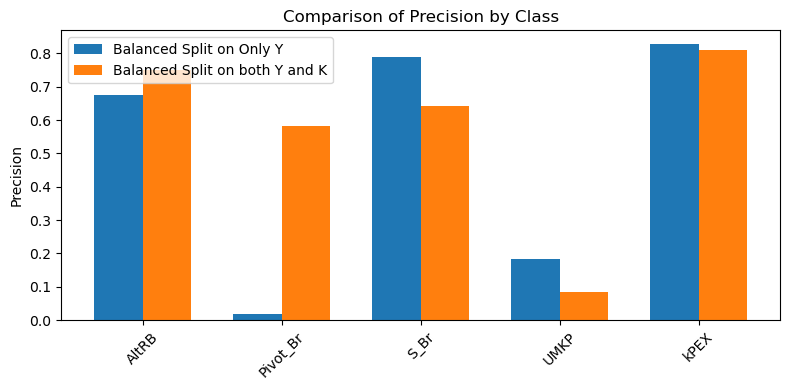

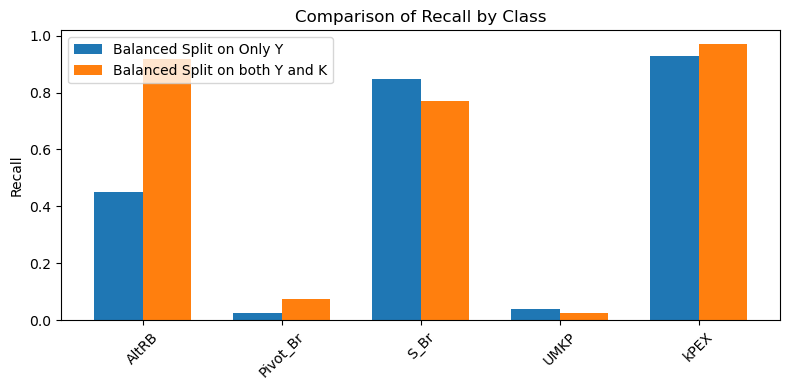

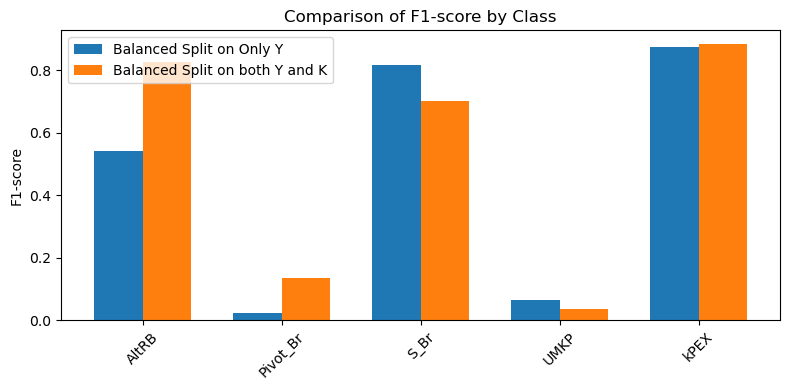

In [59]:
import matplotlib.pyplot as plt

def compare_classification_reports(report_a, report_b, label_a, label_b):
    """
    Plot side‐by‐side comparisons of precision, recall, and F1‐score 
    between two classification reports.

    Parameters
    ----------
    report_a, report_b : dict
        The output of sklearn.metrics.classification_report(..., output_dict=True)
    label_a, label_b : str
        Names to label the two reports/curves in the legend.
    """
    # Extract class names (skip accuracy and averages)
    classes = [c for c in report_a.keys() 
               if c not in ('accuracy','macro avg','weighted avg')]

    metrics = ['precision', 'recall', 'f1-score']
    x = range(len(classes))
    
    # Width for side‐by‐side bars
    width = 0.35

    for metric in metrics:
        fig, ax = plt.subplots(figsize=(8,4))
        
        vals_a = [report_a[c][metric] for c in classes]
        vals_b = [report_b[c][metric] for c in classes]
        
        ax.bar([i - width/2 for i in x], vals_a, width, label=label_a)
        ax.bar([i + width/2 for i in x], vals_b, width, label=label_b)
        
        ax.set_xticks(x)
        ax.set_xticklabels(classes, rotation=45)
        ax.set_ylabel(metric.capitalize())
        ax.set_title(f'Comparison of {metric.capitalize()} by Class')
        ax.legend(loc='best')
        plt.tight_layout()
        plt.show()


compare_classification_reports(report_dict_1, report_dict_2, 'Balanced Split on Only Y', 'Balanced Split on both Y and K')


## Re-evaluate Model on Entire Dataset

Using the model which is trained on balanced train-test split based on Y

In [ ]:
# Create a clean copy of the DataFrame to work with
results_df = cat_df.copy()

# Prepare full dataset features
features = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max', 
           'core_min', 'shell_num', 'shell_avgSize',
           'shell_maxSize', 'shell_minSize', 'shell_stdSize']
X_full = results_df[features]

algorithms = ['UMKP', 'AltRB', 'kPEX', 'Pivot_Br', 'S_Br']

# Define function to get fastest algorithms (including ties)
def get_fastest_algorithms(row):
    times = [row[alg] for alg in algorithms]
    min_time = min(times)
    return [alg for alg in algorithms if row[alg] == min_time]

# Add columns using proper .loc assignment
results_df.loc[:, 'fastest_algorithms'] = results_df.apply(get_fastest_algorithms, axis=1)
y_pred_int = xgb_strat_y.predict(X_full)
y_pred_str = le.inverse_transform(y_pred_int)

# Evalute using model trained on balanced train-test split based on Y
results_df.loc[:, 'predicted'] = y_pred_str

results_df.loc[:, 'correct'] = results_df.apply(
    lambda row: row['predicted'] in row['fastest_algorithms'], 
    axis=1
)


#### Evaluating algorithm performance based on accuracy, precision, and recall.

In [33]:
from metrics import evaluate_algorithm_performance

evaluate_algorithm_performance(results_df, algorithms)

Accuracy (counting ties as correct): 93.42%

Precision by Algorithm:
  UMKP: 94.52% (73 predictions)
  AltRB: 92.55% (94 predictions)
  kPEX: 92.91% (254 predictions)
  Pivot_Br: 91.81% (171 predictions)
  S_Br: 95.83% (168 predictions)

Recall by Algorithm:
  UMKP: 91.00% (91/100 cases)
  AltRB: 94.83% (110/116 cases)
  kPEX: 96.97% (352/363 cases)
  Pivot_Br: 95.58% (216/226 cases)
  S_Br: 94.53% (242/256 cases)


**Print all rows**

In [ ]:
###-- Will go to kplex dev.py --###

# Add prediction probabilities if available
if hasattr(xgb_strat_y, "predict_proba"):
    y_pred_int = xgb_strat_y.predict_proba(X_full)  # XGB predicts integer label
    probabilities = xgb_strat_y.predict_proba(X_full)

    for i, class_name in enumerate(le.classes_):
        results_df.loc[:, f'prob_{class_name}'] = probabilities[:, i]

# Save full results
output_cols = ['dataset', 'k_value', 'fastest_algorithms', 'predicted', 'correct'] + algorithms
if hasattr(xgb_strat_y, "predict_proba"):
    output_cols += [f'prob_{alg}' for alg in algorithms]

results_df[output_cols].to_csv('all_predictions_RF.csv', index=False)
print("\nPredictions saved to 'all_predictions_RF.csv'")


Predictions saved to 'all_predictions_RF.csv'


**Print rows with wrong predictions**

We need to see how serious a prediction is. If a wrong prediction only runs slightly longer than the best, it is totally fine

In [ ]:
###-- Will go to kplex dev.py --###


# Filter for only incorrect predictions and include weights
wrong_predictions = results_df[~results_df['correct']].copy()

# Add weight column if it exists in original data
if 'weight' in results_df.columns:
    wrong_predictions.loc[:, 'weight'] = results_df.loc[~results_df['correct'], 'weight']
else:
    print("Warning: 'weight' column not found in results")

epsilon = 0.001 # user-specified !!!
    
# Calculate time performance metrics
def calculate_time_metrics(row):
    # Get all algorithm times
    algo_times = {alg: row[alg] for alg in algorithms}
    
    # Find fastest time and algorithms
    fastest_time = min(algo_times.values())
    fastest_algos = [alg for alg, t in algo_times.items() if t == fastest_time]
    
    # Get predicted algorithm's time
    predicted_time = algo_times[row['predicted']]
    
    return pd.Series({
        'fastest_time': fastest_time,
        'predicted_time': predicted_time,
        'time_gap': predicted_time - fastest_time,
        'time_ratio': predicted_time / fastest_time if fastest_time > 0 else predicted_time / epsilon
    })

# Add time metrics to wrong predictions
time_metrics = wrong_predictions.apply(calculate_time_metrics, axis=1)
wrong_predictions = pd.concat([wrong_predictions, time_metrics], axis=1)

# Select columns to output (now including time metrics)
output_cols = [
    'dataset', 'k_value', 'weight', 
    'fastest_time', 'predicted_time', 'time_gap', 'time_ratio',
    'fastest_algorithms', 'predicted', 'correct'
] + algorithms

if hasattr(xgb_strat_y, "predict_proba"):
    output_cols += [f'prob_{alg}' for alg in algorithms]

# Sort by weight descending and save
wrong_predictions_sorted = wrong_predictions.sort_values('weight', ascending=False)
wrong_predictions_sorted[output_cols].to_csv('wrong_predictions.csv', index=False)

# Print summary
print(f"\nSaved {len(wrong_predictions_sorted)} wrong predictions with time metrics")
print("\nTop 5 heaviest wrong predictions:")
print(wrong_predictions_sorted[['dataset', 'k_value', 'weight', 'predicted', 'fastest_algorithms', 'time_ratio']].head(5))

# Enhanced error analysis
print("\nError Analysis:")
print(f"Average time ratio: {wrong_predictions_sorted['time_ratio'].mean():.2f}x slower")
print(f"Worst time ratio: {wrong_predictions_sorted['time_ratio'].max():.2f}x slower")
print(f"Best time ratio: {wrong_predictions_sorted['time_ratio'].min():.2f}x slower")
print(f"Median time gap: {wrong_predictions_sorted['time_gap'].median():.2f} seconds")
print(f"Largest time gap: {wrong_predictions_sorted['time_gap'].max():.2f} seconds")
print(f"Smallest time gap: {wrong_predictions_sorted['time_gap'].min():.2f} seconds")

# Error severity breakdown
print("\nError Severity Distribution:")
bins = [1, 1.05, 1.2, 2, float('inf')]
labels = ['<5%', '5-20%', '20-100%', '>100%']
severity = pd.cut(wrong_predictions_sorted['time_ratio'], bins=bins, labels=labels)
print(severity.value_counts().sort_index())

print("\nAlgorithm Error Summary:")
for alg in algorithms:
    alg_errors = wrong_predictions[wrong_predictions['predicted'] == alg]
    avg_ratio = alg_errors['time_ratio'].mean()
    print(f"{alg}: {len(alg_errors)} errors (avg {avg_ratio:.1f}x slower)")


Saved 55 wrong predictions with time metrics

Top 5 heaviest wrong predictions:
                         dataset  k_value      weight predicted  \
684                 wiki_talk_en        2  651.742897      S_Br   
267  soc-livejournal-user-groups        8  472.793073  Pivot_Br   
397                 delicious-ti        6  447.122376  Pivot_Br   
199  soc-livejournal-user-groups        9  277.515866      S_Br   
49   web-wikipedia_link_en13-all       15  276.417754     AltRB   

    fastest_algorithms  time_ratio  
684         [Pivot_Br]    2.298264  
267             [kPEX]    1.003484  
397             [S_Br]    1.030993  
199             [kPEX]    1.003216  
49              [UMKP]    1.065913  

Error Analysis:
Average time ratio: 125.80x slower
Worst time ratio: 6800.00x slower
Best time ratio: 1.00x slower
Median time gap: 0.70 seconds
Largest time gap: 1760.70 seconds
Smallest time gap: 0.10 seconds

Error Severity Distribution:
time_ratio
<5%        20
5-20%      18
20-100%    10

##### Hyperparameter tuning and 5-fold CV on the entire dataset

---NOT REQUIRED---

In [25]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import classification_report

# ——— 1. Prepare your features, target, and weights ————————————————
feature_cols = [
    'k_value', 'n', 'm', 'd_avg', 'd_max',
    'core_max', 'core_min', 'shell_num',
    'shell_avgSize', 'shell_maxSize',
    'shell_minSize', 'shell_stdSize'
]
X           = cat_df[feature_cols]
algorithms  = ['UMKP', 'AltRB', 'kPEX', 'Pivot_Br', 'S_Br']
y      = cat_df[algorithms].idxmin(axis=1)
weights     = cat_df['weight']

# ——— 2. Define parameter grid for Random Forest ————————————————
param_grid_rf = {
    "n_estimators":    [100, 200, 400],
    "max_depth":       [6, 10, 15],
    "min_samples_leaf":[1, 2, 5],
    "min_samples_split":[2, 5, 10]
}

# ——— 3. Set up Stratified K-Fold for CV ————————————————
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# ——— 4. Instantiate base RandomForestClassifier ————————————————
rf_base = RandomForestClassifier(
    class_weight=None,    # we'll use sample_weight instead
    random_state=42,
    n_jobs=-1
)

# ——— 5. Wrap in GridSearchCV ——————————————————————————
grid_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid_rf,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# ——— 6. Fit using sample weights ————————————————————
grid_rf.fit(X, y, sample_weight=weights)

# ——— 7. Inspect best parameters & CV score ——————————————————
print("Best params (RF):", grid_rf.best_params_)
print("Best CV accuracy:", grid_rf.best_score_)




Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best params (RF): {'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 400}
Best CV accuracy: 0.5947368421052632


In [32]:
# ——— 8. (Optional) Evaluate on a held-out test set —————————————
# Assuming you have X_test, y_test_str, weights_test defined:
y_pred = grid_rf.predict(X_test)

print("\nClassification Report on Test Set:")
print(classification_report(
    y_test,
    y_pred,
    sample_weight=weights_test
))

# Feature importance
importances = pd.DataFrame({
    'feature': feature_cols,
    'importance': grid_rf.best_estimator_.feature_importances_
}).sort_values('importance', ascending=False)

print("\nFeature Importances:")
print(importances)


Classification Report on Test Set:
              precision    recall  f1-score   support

       AltRB       1.00      1.00      1.00 1497.8617783752477
    Pivot_Br       0.99      0.84      0.91 1795.5833676176512
        S_Br       0.89      1.00      0.94 2348.663614683116
        UMKP       0.98      1.00      0.99 473.4095218501081
        kPEX       0.99      1.00      1.00 5557.395833511593

    accuracy                           0.97 11672.914116037715
   macro avg       0.97      0.96      0.97 11672.914116037715
weighted avg       0.97      0.97      0.97 11672.914116037715


Feature Importances:
          feature  importance
0         k_value    0.100959
6        core_min    0.100424
4           d_max    0.097164
3           d_avg    0.092682
2               m    0.092118
7       shell_num    0.092093
5        core_max    0.079239
11  shell_stdSize    0.074455
1               n    0.069418
9   shell_maxSize    0.068279
8   shell_avgSize    0.067848
10  shell_minSize    0.0

In [ ]:
# Da: I do not have time to modularize as functions into kplex_dev.py

In [ ]:
# Other possible metrics:
# - total time by predicted models
# - ratio to shortest total time

# Hold-out test set, only use training set to produce multi-label aware training set with duplicate lines (but different labels)

# 5-fold CV

In [11]:
# varying epsilon, scheme, models and their hyperparameters
# - boosting tree models
# <for all other non-tree models, need to normalize features !!!>
# - SVC (rbf, linear)
# - logistic regression (lasso, ridge, elastic net) -> try soft CE loss if use PyTorch rather than sklearn
# - neural networks -> try soft CE loss if use PyTorch rather than sklearn

In [ ]:
# sequence model (LSTM with small number of neurons) + soft CE loss (maybe with temperature)